In [ ]:
"""Bài thực hành 2 — SVM trên dữ liệu động vật trong rừng"""

In [ ]:
"""Đọc dữ liệu và kiểm tra cấu trúc"""

In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay
)

In [3]:
df_animals = pd.read_csv("animal_condition.csv")

print("Kích thước:", df_animals.shape)
print("\nCác cột:")
print(df_animals.columns.tolist())

display(df_animals.head())
display(df_animals.describe(include="all").T)

print("\nSố lượng giá trị thiếu:")
print(df_animals.isnull().sum())

Kích thước: (871, 7)

Các cột:
['AnimalName', 'symptoms1', 'symptoms2', 'symptoms3', 'symptoms4', 'symptoms5', 'Dangerous']


,AnimalName,symptoms1,symptoms2,symptoms3,symptoms4,symptoms5,Dangerous
0,Dog,Fever,Diarrhea,Vomiting,Weight loss,Dehydration,Yes
1,Dog,Fever,Diarrhea,Coughing,Tiredness,Pains,Yes
2,Dog,Fever,Diarrhea,Coughing,Vomiting,Anorexia,Yes
3,Dog,Fever,Difficulty breathing,Coughing,Lethargy,Sneezing,Yes
4,Dog,Fever,Diarrhea,Coughing,Lethargy,Blue Eye,Yes


,count,unique,top,freq
AnimalName,871,46,Buffaloes,129
symptoms1,871,232,Fever,257
symptoms2,871,230,Diarrhea,119
symptoms3,871,229,Coughing,95
symptoms4,871,217,Weight loss,117
symptoms5,871,203,Pains,99
Dangerous,869,2,Yes,849



Số lượng giá trị thiếu:
AnimalName    0
symptoms1     0
symptoms2     0
symptoms3     0
symptoms4     0
symptoms5     0
Dangerous     2
dtype: int64


In [ ]:
"""Chọn nhãn cần dự đoán"""

In [5]:

target_col = "symptoms1"

assert target_col in df_animals.columns, (
    f"Không tìm thấy cột {target_col}. "
    f"Các cột hiện có: {df_animals.columns.tolist()}"
)

df = df_animals.dropna(subset=[target_col]).copy()

X = df.drop(columns=[target_col])
y = df[target_col].astype(str)

print("Phân bố nhãn:")
print(y.value_counts())

Phân bố nhãn:
symptoms1
Fever                      257
Fetopelvic dispropotion     21
wasting                     20
fever                       14
loss of appetite            12
                          ... 
Head Shking                  1
Inflammation                 1
Isolation from flock         1
Bluish white opacity         1
Head tossing                 1
Name: count, Length: 232, dtype: int64


In [6]:
target_col = "symptoms2"

assert target_col in df_animals.columns, (
    f"Không tìm thấy cột {target_col}. "
    f"Các cột hiện có: {df_animals.columns.tolist()}"
)

df = df_animals.dropna(subset=[target_col]).copy()

X = df.drop(columns=[target_col])
y = df[target_col].astype(str)

print("Phân bố nhãn:")
print(y.value_counts())

Phân bố nhãn:
symptoms2
Diarrhea                   119
Difficulty in breathing     26
Loss of appetite            26
Depression                  26
Uteria inertia              21
                          ... 
Larynx                       1
Stealing                     1
Difficulty in walking        1
Aversion to light            1
Diffulty Swallowing          1
Name: count, Length: 230, dtype: int64


In [7]:
target_col = "symptoms3"

assert target_col in df_animals.columns, (
    f"Không tìm thấy cột {target_col}. "
    f"Các cột hiện có: {df_animals.columns.tolist()}"
)

df = df_animals.dropna(subset=[target_col]).copy()

X = df.drop(columns=[target_col])
y = df[target_col].astype(str)

print("Phân bố nhãn:")
print(y.value_counts())

Phân bố nhãn:
symptoms3
Coughing              95
Vomiting              59
loss of appetite      28
Lethargy              22
Malpresentation       22
                      ..
Swelling on jaw        1
Nesting behaviour      1
Grinding of teeth      1
Tear produce           1
Excessive drooling     1
Name: count, Length: 229, dtype: int64


In [8]:
target_col = "symptoms4"

assert target_col in df_animals.columns, (
    f"Không tìm thấy cột {target_col}. "
    f"Các cột hiện có: {df_animals.columns.tolist()}"
)

df = df_animals.dropna(subset=[target_col]).copy()

X = df.drop(columns=[target_col])
y = df[target_col].astype(str)

print("Phân bố nhãn:")
print(y.value_counts())

Phân bố nhãn:
symptoms4
Weight loss          117
Death                 51
Lethargy              47
Depression            28
Weakness              25
                    ... 
Profuse                1
Hoarseness             1
Urine infection        1
Pawing at bedding      1
Bleeding wounds        1
Name: count, Length: 217, dtype: int64


In [9]:
target_col = "symptoms5"

assert target_col in df_animals.columns, (
    f"Không tìm thấy cột {target_col}. "
    f"Các cột hiện có: {df_animals.columns.tolist()}"
)

df = df_animals.dropna(subset=[target_col]).copy()

X = df.drop(columns=[target_col])
y = df[target_col].astype(str)

print("Phân bố nhãn:")
print(y.value_counts())

Phân bố nhãn:
symptoms5
Pains                 99
Pain                  68
Anorexia              37
Nasal Discharge       37
Weight loss           24
                      ..
lameness               2
Blister                1
Redness on ear         1
Neck Vein Swelling     1
weakness               1
Name: count, Length: 203, dtype: int64


In [11]:
target_col = "Dangerous"

assert target_col in df_animals.columns, (
    f"Không tìm thấy cột {target_col}. "
    f"Các cột hiện có: {df_animals.columns.tolist()}"
)

df = df_animals.dropna(subset=[target_col]).copy()

X = df.drop(columns=[target_col])
y = df[target_col].astype(str)

print("Phân bố nhãn:")
print(y.value_counts())

Phân bố nhãn:
Dangerous
Yes    849
No      20
Name: count, dtype: int64


In [ ]:
"""Tiền xử lý và huấn luyện SVM"""

In [15]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC

numeric_cols = X.select_dtypes(
    include=np.number
).columns.tolist()

categorical_cols = X.select_dtypes(
    exclude=np.number
).columns.tolist()

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_cols),
    ("categorical", categorical_pipeline, categorical_cols)
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

svm_animals = Pipeline([
    ("preprocessor", preprocessor),
    ("svm", SVC(
        kernel="rbf",
        C=1.0,
        gamma="scale",
        class_weight="balanced"
    ))
])

svm_animals.fit(X_train, y_train)

y_pred_animals = svm_animals.predict(X_test)

print("Accuracy:", round(
    accuracy_score(y_test, y_pred_animals), 4
))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_animals,
    zero_division=0
))

Accuracy: 1.0

Classification Report:
              precision    recall  f1-score   support

          No       1.00      1.00      1.00         4
         Yes       1.00      1.00      1.00       170

    accuracy                           1.00       174
   macro avg       1.00      1.00      1.00       174
weighted avg       1.00      1.00      1.00       174



In [ ]:
"""Ma trận nhầm lẫn"""

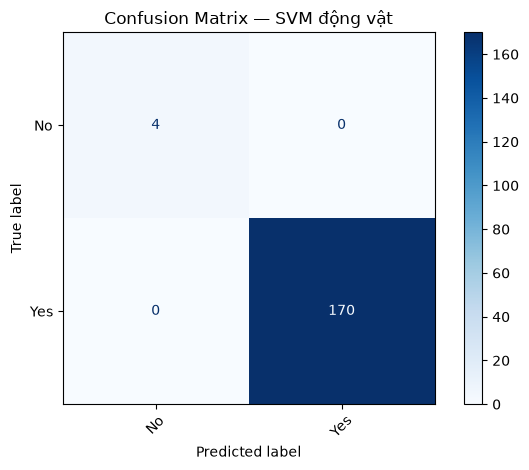

In [16]:
labels = sorted(y.unique())

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_animals,
    labels=labels,
    xticks_rotation=45,
    cmap="Blues",
    values_format="d"
)

plt.title("Confusion Matrix — SVM động vật")
plt.tight_layout()
plt.show()